# Salted password verifiers

Create and verify independent salted records for a single demonstration passphrase held only in memory.

A verifier stores a salt, cost parameters and a slow derived value. This example uses the OWASP scrypt configuration N = 2¹⁷, r = 8 and p = 1. Verification recomputes the derivation with the stored parameters and compares fixed-length bytes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hashlib, hmac, secrets

## Run the local experiment

All records used below belong to the small fixture supplied by the example.

same record / different salt / different value [True, False, False]


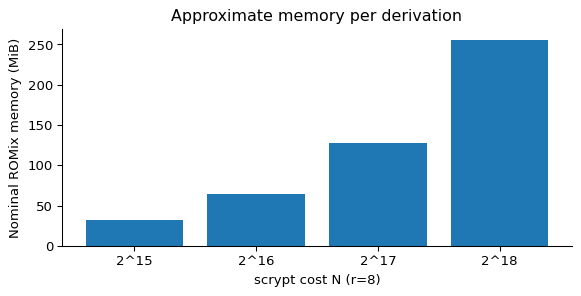

In [2]:
n, r, p = 2**17, 8, 1


def derive(value, salt):
    return hashlib.scrypt(value, salt=salt, n=n, r=r, p=p, maxmem=256 * 1024**2, dklen=32)


phrase = secrets.token_bytes(24)
s1, s2 = secrets.token_bytes(16), secrets.token_bytes(16)
a, b = derive(phrase, s1), derive(phrase, s2)
checks = [
    hmac.compare_digest(a, derive(phrase, s1)),
    hmac.compare_digest(a, b),
    hmac.compare_digest(a, derive(secrets.token_bytes(24), s1)),
]
print("same record / different salt / different value", checks)
assert checks == [True, False, False]
ns = np.array([2**15, 2**16, 2**17, 2**18])
fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
ax.bar([f"2^{int(np.log2(x))}" for x in ns], 128 * ns * r / (1024**2))
ax.set(
    xlabel="scrypt cost N (r=8)",
    ylabel="Nominal ROMix memory (MiB)",
    title="Approximate memory per derivation",
)
plt.show()

## Interpreting the result

The memory bars use 128 × N × r bytes for the main working array. Actual process memory includes implementation overhead.

## Exercise

Determine a memory budget for two independent verifications at the demonstrated cost.

## References

[OWASP, Password Storage Cheat Sheet](https://cheatsheetseries.owasp.org/cheatsheets/Password_Storage_Cheat_Sheet.html)

[Python, hashlib](https://docs.python.org/3/library/hashlib.html)